starting with looking at dataset


In [1]:
import pandas as pd
df = pd.read_csv("/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/Data-Analysis-with-Python-HS2026/Project Education/Data_educ/Download_data_education_swiss.csv")
df

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES
0,2024/25,Total,_T__,_T,_T,_T,217096.00,abs
1,2024/25,Total,_T__,_F,_T,_T,41.03,pct
2,2024/25,Total,_T__,_T,_E,_T,24.78,pct
3,2024/25,Total,_T__,_T,_T,_P,2.13,pct
4,2024/25,Field,F0011,_T,_T,_T,18.00,abs
...,...,...,...,...,...,...,...,...
4705,1999/00,Form,A,_T,_E,_T,15.67,pct
4706,1999/00,Form,P,_T,_E,_T,23.64,pct
4707,1999/00,Form,S,_T,_T,_P,8.18,pct
4708,1999/00,Form,A,_T,_T,_P,0.55,pct


In [2]:
data = df.copy()
print(data.columns)

Index(['PERIOD', 'INDICATOR', 'INDIC_CODE', 'SEX', 'NAT', 'STAT', 'VALUE',
       'UNIT_MES'],
      dtype='str')


In [3]:
data = df.copy()
data["SEX"] = data["SEX"].str.strip("_") #stripping SEX so that it is just a Letters/Nubmers value
data["NAT"] = data["NAT"].str.strip("_")
data["STAT"] = data["STAT"].str.strip("_")
data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES
0,2024/25,Total,_T__,T,T,T,217096.00,abs
1,2024/25,Total,_T__,F,T,T,41.03,pct
2,2024/25,Total,_T__,T,E,T,24.78,pct
3,2024/25,Total,_T__,T,T,P,2.13,pct
4,2024/25,Field,F0011,T,T,T,18.00,abs
...,...,...,...,...,...,...,...,...
4705,1999/00,Form,A,T,E,T,15.67,pct
4706,1999/00,Form,P,T,E,T,23.64,pct
4707,1999/00,Form,S,T,T,P,8.18,pct
4708,1999/00,Form,A,T,T,P,0.55,pct


In [4]:
data[data["INDIC_CODE"] == "F9999"] #looking if we have unkonowns for industry in the dataset
data = data[data["INDIC_CODE"] != "F9999"] #dropping said datapoints
data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES
0,2024/25,Total,_T__,T,T,T,217096.00,abs
1,2024/25,Total,_T__,F,T,T,41.03,pct
2,2024/25,Total,_T__,T,E,T,24.78,pct
3,2024/25,Total,_T__,T,T,P,2.13,pct
4,2024/25,Field,F0011,T,T,T,18.00,abs
...,...,...,...,...,...,...,...,...
4705,1999/00,Form,A,T,E,T,15.67,pct
4706,1999/00,Form,P,T,E,T,23.64,pct
4707,1999/00,Form,S,T,T,P,8.18,pct
4708,1999/00,Form,A,T,T,P,0.55,pct


In [5]:
data = data[data["PERIOD"] != "1999/00"]#dropping all data from period 1999

sorted_periods = sorted(data["PERIOD"].unique())

period_mapping = {}
for index, period in enumerate(sorted_periods):
    period_mapping[period] = index

data["PERIOD_norm"] = data["PERIOD"].map(period_mapping)

data

#print(sorted(data["PERIOD"].unique())) #looking at what periods we all have



,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES,PERIOD_norm
0,2024/25,Total,_T__,T,T,T,217096.00,abs,24
1,2024/25,Total,_T__,F,T,T,41.03,pct,24
2,2024/25,Total,_T__,T,E,T,24.78,pct,24
3,2024/25,Total,_T__,T,T,P,2.13,pct,24
4,2024/25,Field,F0011,T,T,T,18.00,abs,24
...,...,...,...,...,...,...,...,...,...
4519,2000/01,Form,A,T,E,T,15.56,pct,0
4520,2000/01,Form,P,T,E,T,26.25,pct,0
4521,2000/01,Form,S,T,T,P,7.29,pct,0
4522,2000/01,Form,A,T,T,P,0.72,pct,0


In [6]:
data = data.reset_index(drop=True) #so that it does not regard dropped datapoints

for pos, i in enumerate(data["INDIC_CODE"]): #creating real groups for the INDIC to make analysis easier
    if len(str(i)) == 5:
        data.loc[pos, "Indic_group"] = i[:3]
    elif str(i) == "_T__":
        data.loc[pos, "Indic_group"] = i[1]
    else: 
        data.loc[pos, "Indic_group"] = "N/A"

data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES,PERIOD_norm,Indic_group
0,2024/25,Total,_T__,T,T,T,217096.00,abs,24,T
1,2024/25,Total,_T__,F,T,T,41.03,pct,24,T
2,2024/25,Total,_T__,T,E,T,24.78,pct,24,T
3,2024/25,Total,_T__,T,T,P,2.13,pct,24,T
4,2024/25,Field,F0011,T,T,T,18.00,abs,24,F00
...,...,...,...,...,...,...,...,...,...,...
4464,2000/01,Form,A,T,E,T,15.56,pct,0,N/A
4465,2000/01,Form,P,T,E,T,26.25,pct,0,N/A
4466,2000/01,Form,S,T,T,P,7.29,pct,0,N/A
4467,2000/01,Form,A,T,T,P,0.72,pct,0,N/A


In [7]:
data = data[data["Indic_group"] != "N/A"] #dropping all N/As bc I only want to look at 
data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES,PERIOD_norm,Indic_group
0,2024/25,Total,_T__,T,T,T,217096.00,abs,24,T
1,2024/25,Total,_T__,F,T,T,41.03,pct,24,T
2,2024/25,Total,_T__,T,E,T,24.78,pct,24,T
3,2024/25,Total,_T__,T,T,P,2.13,pct,24,T
4,2024/25,Field,F0011,T,T,T,18.00,abs,24,F00
...,...,...,...,...,...,...,...,...,...,...
4408,2000/01,Field,F0913,T,T,P,0.13,pct,0,F09
4409,2000/01,Field,F0914,T,T,P,29.51,pct,0,F09
4410,2000/01,Field,F0922,T,T,P,9.61,pct,0,F09
4411,2000/01,Field,F1012,T,T,P,5.65,pct,0,F10


In [8]:
#data = ((data[data["Indic_group"] != "T"]) & (data[data["Indic_group"] != "F09"])) #dropping all useless data
data = data[(data["Indic_group"] == "T") | (data["Indic_group"] == "F09")]
data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES,PERIOD_norm,Indic_group
0,2024/25,Total,_T__,T,T,T,217096.00,abs,24,T
1,2024/25,Total,_T__,F,T,T,41.03,pct,24,T
2,2024/25,Total,_T__,T,E,T,24.78,pct,24,T
3,2024/25,Total,_T__,T,T,P,2.13,pct,24,T
31,2024/25,Field,F0911,T,T,T,3520.00,abs,24,F09
...,...,...,...,...,...,...,...,...,...,...
4389,2000/01,Field,F0923,T,E,T,4.69,pct,0,F09
4407,2000/01,Field,F0911,T,T,P,9.13,pct,0,F09
4408,2000/01,Field,F0913,T,T,P,0.13,pct,0,F09
4409,2000/01,Field,F0914,T,T,P,29.51,pct,0,F09


In [9]:
data = ((data[data["NAT"] == "T"])) #dropping irrelevant datapoints
data = ((data[data["STAT"] == "T"]))
data = ((data[data["SEX"] == "T"]))
data

,PERIOD,INDICATOR,INDIC_CODE,SEX,NAT,STAT,VALUE,UNIT_MES,PERIOD_norm,Indic_group
0,2024/25,Total,_T__,T,T,T,217096.0,abs,24,T
31,2024/25,Field,F0911,T,T,T,3520.0,abs,24,F09
32,2024/25,Field,F0913,T,T,T,14080.0,abs,24,F09
33,2024/25,Field,F0914,T,T,T,4896.0,abs,24,F09
34,2024/25,Field,F0916,T,T,T,2838.0,abs,24,F09
...,...,...,...,...,...,...,...,...,...,...
4312,2000/01,Field,F0913,T,T,T,12385.0,abs,0,F09
4313,2000/01,Field,F0914,T,T,T,4382.0,abs,0,F09
4314,2000/01,Field,F0921,T,T,T,206.0,abs,0,F09
4315,2000/01,Field,F0922,T,T,T,801.0,abs,0,F09


In [10]:
data = ((data[data["UNIT_MES"] == "abs"])) #for the moment I only want to look at absolute values
 

In [11]:
t_data = data[data["Indic_group"] == "T"] #creating table with only T
f09_data = data[data["Indic_group"] == "F09"] #creating table with only F09

print(len(t_data), len(f09_data)) #sanity check --> this makes sense since for total we should have exactly 25 datapoints

25 144


In [12]:
t_sum = t_data.groupby("PERIOD_norm")["VALUE"].sum()
f09_sum = f09_data.groupby("PERIOD_norm")["VALUE"].sum()

print(t_sum)
print(f09_sum)

PERIOD_norm
0     207969.0
1     210304.0
2     210997.0
3     212146.0
4     211384.0
5     213174.0
6     218709.0
7     219354.0
8     225008.0
9     229079.0
10    228575.0
11    231439.0
12    229807.0
13    229230.0
14    229581.0
15    226822.0
16    224776.0
17    223047.0
18    219914.0
19    217767.0
20    215596.0
21    215609.0
22    213017.0
23    214621.0
24    217096.0
Name: VALUE, dtype: float64
PERIOD_norm
0     20004.0
1     20127.0
2     20382.0
3     21383.0
4     21825.0
5     21805.0
6     23683.0
7     18314.0
8     19402.0
9     21893.0
10    23662.0
11    25404.0
12    26489.0
13    27925.0
14    29185.0
15    30166.0
16    31534.0
17    32719.0
18    33739.0
19    34342.0
20    34419.0
21    35190.0
22    36493.0
23    38688.0
24    40905.0
Name: VALUE, dtype: float64


In [13]:
t_cum = t_sum.cumsum() #cummulative values
print(t_cum)

f09_cum = f09_sum.cumsum()
print(f09_cum)

PERIOD_norm
0      207969.0
1      418273.0
2      629270.0
3      841416.0
4     1052800.0
5     1265974.0
6     1484683.0
7     1704037.0
8     1929045.0
9     2158124.0
10    2386699.0
11    2618138.0
12    2847945.0
13    3077175.0
14    3306756.0
15    3533578.0
16    3758354.0
17    3981401.0
18    4201315.0
19    4419082.0
20    4634678.0
21    4850287.0
22    5063304.0
23    5277925.0
24    5495021.0
Name: VALUE, dtype: float64
PERIOD_norm
0      20004.0
1      40131.0
2      60513.0
3      81896.0
4     103721.0
5     125526.0
6     149209.0
7     167523.0
8     186925.0
9     208818.0
10    232480.0
11    257884.0
12    284373.0
13    312298.0
14    341483.0
15    371649.0
16    403183.0
17    435902.0
18    469641.0
19    503983.0
20    538402.0
21    573592.0
22    610085.0
23    648773.0
24    689678.0
Name: VALUE, dtype: float64


In [14]:
#regression (from Claude):

import numpy as np

slope, intercept = np.polyfit(t_cum, f09_cum, 1)
r = np.corrcoef(t_cum, f09_cum)[0, 1]

print("Slope:", slope)
print("Intercept:", intercept)
print("R-squared:", r ** 2)

Slope: 0.12319592481022362
Intercept: -37875.454182360445
R-squared: 0.9867378939021618


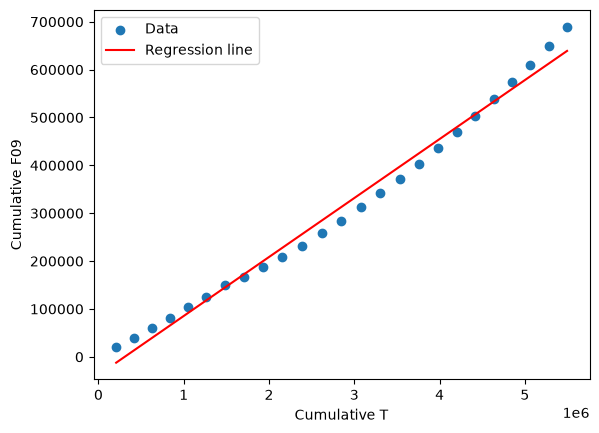

In [ ]:
#first graph: got the frame for plots with matplotlib from Claude and tried to build it myself

import matplotlib.pyplot as plt

plt.scatter(t_cum, f09_cum, label="Data")
plt.plot(t_cum, intercept + slope * t_cum, color="red", label="Regression line")
plt.xlabel("Cumulative T")
plt.ylabel("Cumulative F09")
plt.legend()

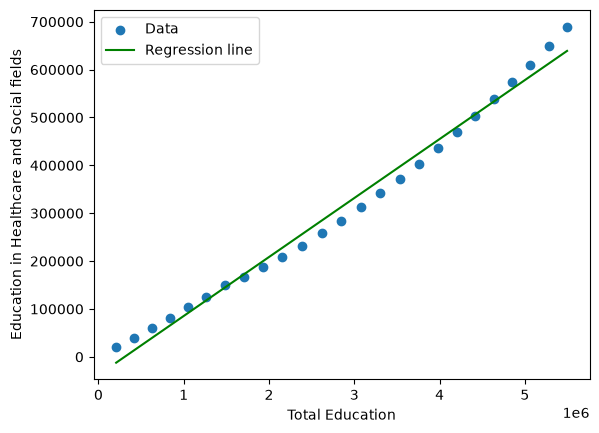

In [ ]:
plt.scatter(t_cum, f09_cum, label="Data")
plt.plot(t_cum, intercept + slope * t_cum, color="green", label="Regression line")
plt.xlabel("Total Education")
plt.ylabel("Education in Healthcare and Social fields")
plt.legend()

In [19]:
#sanity check:
share = f09_sum / t_sum * 100
print(share)

PERIOD_norm
0      9.618741
1      9.570431
2      9.659853
3     10.079379
4     10.324812
5     10.228733
6     10.828544
7      8.349061
8      8.622805
9      9.556965
10    10.351963
11    10.976542
12    11.526629
13    12.182088
14    12.712289
15    13.299415
16    14.029078
17    14.669106
18    15.341906
19    15.770066
20    15.964582
21    16.321211
22    17.131497
23    18.026195
24    18.841895
Name: VALUE, dtype: float64


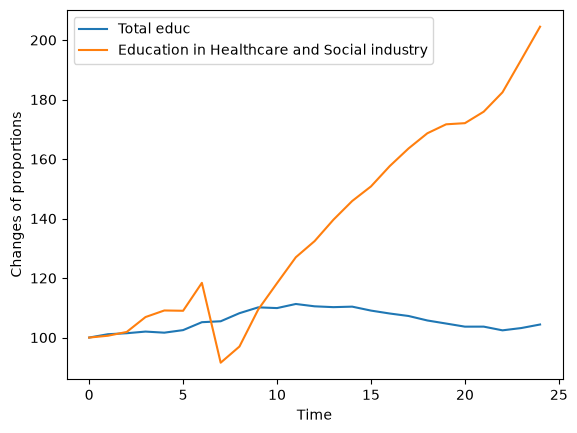

In [ ]:
#looking at changes over time


#t_index = t_sum / t_sum.i * 100  --> does not work bc location was missing
#f09_index = f09_sum / f09_sum.i * 100
t_index = t_sum / t_sum.iloc[0] * 100 #normalizing over time
f09_index = f09_sum / f09_sum.iloc[0] * 100

plt.plot(t_index.index, t_index, label="Total educ")
plt.plot(f09_index.index, f09_index, label="Education in Healthcare and Social industry")
plt.xlabel("Time")
plt.ylabel("Changes of proportions")
plt.legend()